# 03 — Personalización en Google Colab GPU (Scratch vs. Fine-Tuning sobre Trazos Reales)

Este notebook realiza la fase de adaptación al estilo manuscrito personal en GPU (**Entorno de ejecución → Cambiar tipo de entorno → T4 GPU**), manteniendo intacto `02_colab_training.ipynb`:
1. Montaje de **Google Drive** (`MyDrive/handwritten-font-cgan`) donde residen los pesos preentrenados (`pix2pix_pretrained.pth`, `judge_resnet18.pth`, `judge_efficientnet_b0.pth`).
2. Clonación / actualización del repositorio `handwritten-font-cgan`.
3. Carga de tus **300 pares reales** (`data/real_pairs/`) desde `real_pairs.zip` (o carpeta `real_pairs/`) en Drive.
4. **Experimento B (Principal):** *Fine-tuning* de **Pix2Pix** partiendo de `pix2pix_pretrained.pth` → `checkpoints/pix2pix_finetuned.pth`.
5. **Experimento A (Comparativa):** Entrenamiento *From Scratch* sobre tus datos reales → `checkpoints/pix2pix_scratch.pth`.
6. Visualización de curvas, cuadrículas `x | ŷ | y` (`val` y `test_unseen` Zero-Shot) y evaluación cuantitativa comparativa (`eval.evaluate_models --tag final`).

> **Requisito previo:** Sube el archivo `data/real_pairs.zip` (o la carpeta `real_pairs/`) a tu carpeta de Google Drive: `MyDrive/handwritten-font-cgan/`.

In [1]:
# 1. Verificar GPU, montar Google Drive y validar checkpoints preentrenados
from pathlib import Path
import torch
from google.colab import drive

print("PyTorch:", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ADVERTENCIA: No hay GPU activa. Activa GPU en Entorno de ejecución -> Cambiar tipo de entorno.")

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/handwritten-font-cgan")
CKPT_DIR = DRIVE_ROOT / "checkpoints"
FIG_DIR = DRIVE_ROOT / "figuras"
RES_DIR = DRIVE_ROOT / "results"
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

required_ckpts = [
    "pix2pix_pretrained.pth",
    "judge_resnet18.pth",
    "judge_efficientnet_b0.pth",
]
for name in required_ckpts:
    p = CKPT_DIR / name
    status = "OK" if p.exists() else "FALTA"
    print(f"  [{status}] {p}")

assert (CKPT_DIR / "pix2pix_pretrained.pth").exists(), (
    "Falta checkpoints/pix2pix_pretrained.pth en Google Drive. "
    "Ejecuta primero 02_colab_training.ipynb o sube el checkpoint a Drive."
)

PyTorch: 2.14.1+cu130 | CUDA disponible: True
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  [OK] /content/drive/MyDrive/handwritten-font-cgan/checkpoints/pix2pix_pretrained.pth
  [OK] /content/drive/MyDrive/handwritten-font-cgan/checkpoints/judge_resnet18.pth
  [OK] /content/drive/MyDrive/handwritten-font-cgan/checkpoints/judge_efficientnet_b0.pth


In [2]:
# 2. Clonar o actualizar el repositorio desde GitHub
import os
import subprocess

REPO_URL = "https://github.com/carloamezcua/handwritten-font-cgan.git"
REPO_DIR = Path("/content/handwritten-font-cgan")

if (REPO_DIR / ".git").exists():
    res = subprocess.run(["git", "-C", str(REPO_DIR), "pull"], capture_output=True, text=True)
    if res.returncode != 0:
        print("git pull falló, reclonando limpio...", res.stderr)
        import shutil
        shutil.rmtree(REPO_DIR)
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    if REPO_DIR.exists():
        import shutil
        shutil.rmtree(REPO_DIR)
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)
print("Directorio actual:", os.getcwd())

!pip install -q fonttools

Directorio actual: /content/handwritten-font-cgan


In [3]:
# 3. Cargar data/real_pairs/ desde Google Drive (acepta real_pairs.zip o carpeta real_pairs/)
import shutil
import zipfile
import csv
from collections import Counter

LOCAL_REAL_DIR = Path("data/real_pairs")
DRIVE_ZIP = DRIVE_ROOT / "real_pairs.zip"
DRIVE_FOLDER = DRIVE_ROOT / "real_pairs"

if LOCAL_REAL_DIR.exists():
    shutil.rmtree(LOCAL_REAL_DIR)

if DRIVE_ZIP.exists():
    print(f"Descomprimiendo {DRIVE_ZIP} ...")
    tmp_extract = Path("/content/_tmp_real_pairs")
    if tmp_extract.exists():
        shutil.rmtree(tmp_extract)
    with zipfile.ZipFile(DRIVE_ZIP, "r") as zf:
        for info in zf.infolist():
            rel = info.filename.replace("\\", "/")
            if not rel or rel.endswith("/"):
                continue
            target = tmp_extract / rel
            target.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(info) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)
    # Soportar tanto zip con carpeta raíz `real_pairs/` como contenido directo
    if (tmp_extract / "real_pairs" / "metadata.csv").exists():
        shutil.move(str(tmp_extract / "real_pairs"), str(LOCAL_REAL_DIR))
    elif (tmp_extract / "metadata.csv").exists():
        shutil.move(str(tmp_extract), str(LOCAL_REAL_DIR))
    else:
        raise FileNotFoundError("No se encontró metadata.csv dentro de real_pairs.zip")
    if tmp_extract.exists():
        shutil.rmtree(tmp_extract)
elif DRIVE_FOLDER.exists():
    print(f"Copiando carpeta {DRIVE_FOLDER} -> {LOCAL_REAL_DIR} ...")
    shutil.copytree(DRIVE_FOLDER, LOCAL_REAL_DIR)
else:
    raise FileNotFoundError(
        f"No se encontró {DRIVE_ZIP} ni {DRIVE_FOLDER}. "
        "Sube data/real_pairs.zip a MyDrive/handwritten-font-cgan/ antes de ejecutar."
    )

meta_path = LOCAL_REAL_DIR / "metadata.csv"
assert meta_path.exists(), f"No se encontró {meta_path}"

with meta_path.open("r", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
counts = Counter(r["split"] for r in rows)
print(f"[OK] Dataset real listo en {LOCAL_REAL_DIR}: {len(rows)} muestras -> {dict(counts)}")

Descomprimiendo /content/drive/MyDrive/handwritten-font-cgan/real_pairs.zip ...
[OK] Dataset real listo en data/real_pairs: 300 muestras -> {'train': 192, 'test_unseen': 44, 'val': 64}


In [4]:
# 4. Experimento B (Principal): Fine-Tuning de Pix2Pix sobre tus trazos reales
PRETRAINED_CKPT = CKPT_DIR / "pix2pix_pretrained.pth"

!python -m src.train.train_pix2pix \
    --mode finetune \
    --data-dir data/real_pairs \
    --pretrained-ckpt "{PRETRAINED_CKPT}" \
    --checkpoints-dir "{CKPT_DIR}" \
    --figures-dir "{FIG_DIR}" \
    --results-dir "{RES_DIR / 'pix2pix'}" \
    --epochs 100 \
    --batch-size 16 \
    --lr 1e-4 \
    --sample-every 10 \
    --num-workers 2

[INFO] Pesos preentrenados cargados desde: /content/drive/MyDrive/handwritten-font-cgan/checkpoints/pix2pix_pretrained.pth

=== Entrenando Pix2Pix (mode=finetune, epochs=100, batch_size=16, lr=0.0001, device=cuda) ===
  Época 001/100 | d_loss=0.5112 | g_adv=1.4200 | train_l1=0.0664 | val_l1=0.0595 | lr=1.00e-04
  Época 002/100 | d_loss=0.4858 | g_adv=1.4775 | train_l1=0.0619 | val_l1=0.0639 | lr=1.00e-04
  Época 003/100 | d_loss=0.4586 | g_adv=1.4548 | train_l1=0.0618 | val_l1=0.0643 | lr=1.00e-04
  Época 004/100 | d_loss=0.5180 | g_adv=1.4814 | train_l1=0.0631 | val_l1=0.0642 | lr=1.00e-04
  Época 005/100 | d_loss=0.5654 | g_adv=1.2942 | train_l1=0.0632 | val_l1=0.0640 | lr=1.00e-04
  Época 006/100 | d_loss=0.5672 | g_adv=1.3520 | train_l1=0.0636 | val_l1=0.0648 | lr=1.00e-04
  Época 007/100 | d_loss=0.5081 | g_adv=1.3728 | train_l1=0.0622 | val_l1=0.0627 | lr=1.00e-04
  Época 008/100 | d_loss=0.5455 | g_adv=1.2326 | train_l1=0.0621 | val_l1=0.0589 | lr=1.00e-04
  Época 009/100 | d_lo

In [5]:
# 5. Experimento A (Comparativa opcional): Entrenamiento From Scratch sobre tus trazos reales
# Cambia a False si solo quieres entrenar el fine-tuning.
RUN_SCRATCH = True

if RUN_SCRATCH:
    !python -m src.train.train_pix2pix \
        --mode scratch \
        --data-dir data/real_pairs \
        --checkpoints-dir "{CKPT_DIR}" \
        --figures-dir "{FIG_DIR}" \
        --results-dir "{RES_DIR / 'pix2pix'}" \
        --epochs 150 \
        --batch-size 16 \
        --lr 2e-4 \
        --sample-every 15 \
        --num-workers 2
else:
    print("Entrenamiento From Scratch omitido (RUN_SCRATCH=False).")


=== Entrenando Pix2Pix (mode=scratch, epochs=150, batch_size=16, lr=0.0002, device=cuda) ===
  Época 001/150 | d_loss=0.5936 | g_adv=1.7741 | train_l1=0.9162 | val_l1=0.8794 | lr=2.00e-04
  Época 002/150 | d_loss=0.2493 | g_adv=3.2834 | train_l1=0.6159 | val_l1=0.5720 | lr=2.00e-04
  Época 003/150 | d_loss=0.1983 | g_adv=4.0009 | train_l1=0.4119 | val_l1=0.2974 | lr=2.00e-04
  Época 004/150 | d_loss=0.6741 | g_adv=3.0581 | train_l1=0.2748 | val_l1=0.1722 | lr=2.00e-04
  Época 005/150 | d_loss=0.5447 | g_adv=1.9548 | train_l1=0.1883 | val_l1=0.1242 | lr=2.00e-04
  Época 006/150 | d_loss=0.3056 | g_adv=2.6173 | train_l1=0.1377 | val_l1=0.1078 | lr=2.00e-04
  Época 007/150 | d_loss=0.4875 | g_adv=2.1736 | train_l1=0.1101 | val_l1=0.0924 | lr=2.00e-04
  Época 008/150 | d_loss=0.2562 | g_adv=2.7744 | train_l1=0.0998 | val_l1=0.0799 | lr=2.00e-04
  Época 009/150 | d_loss=0.2029 | g_adv=3.3020 | train_l1=0.0876 | val_l1=0.0842 | lr=2.00e-04
  Época 010/150 | d_loss=0.2083 | g_adv=3.2898 | tr


--- train_pix2pix_finetune.png ---


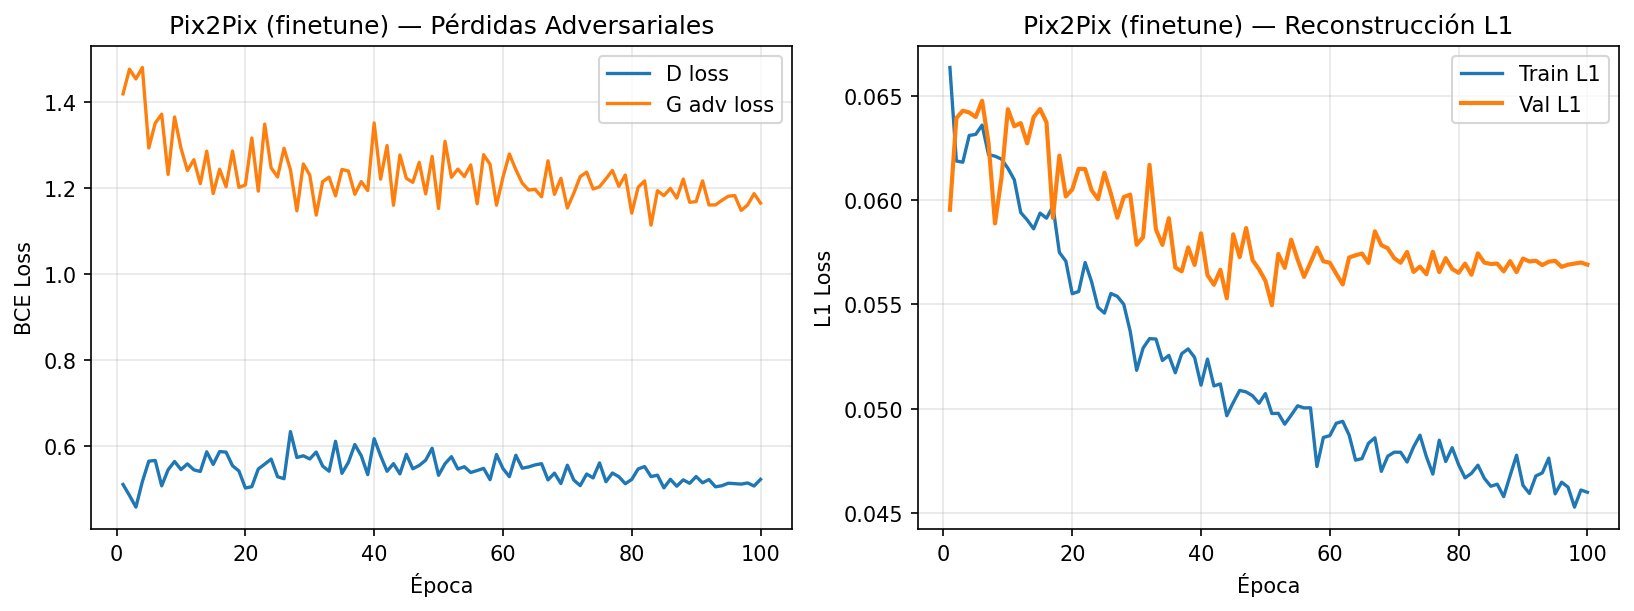


--- pix2pix_finetune_val_grid.png ---


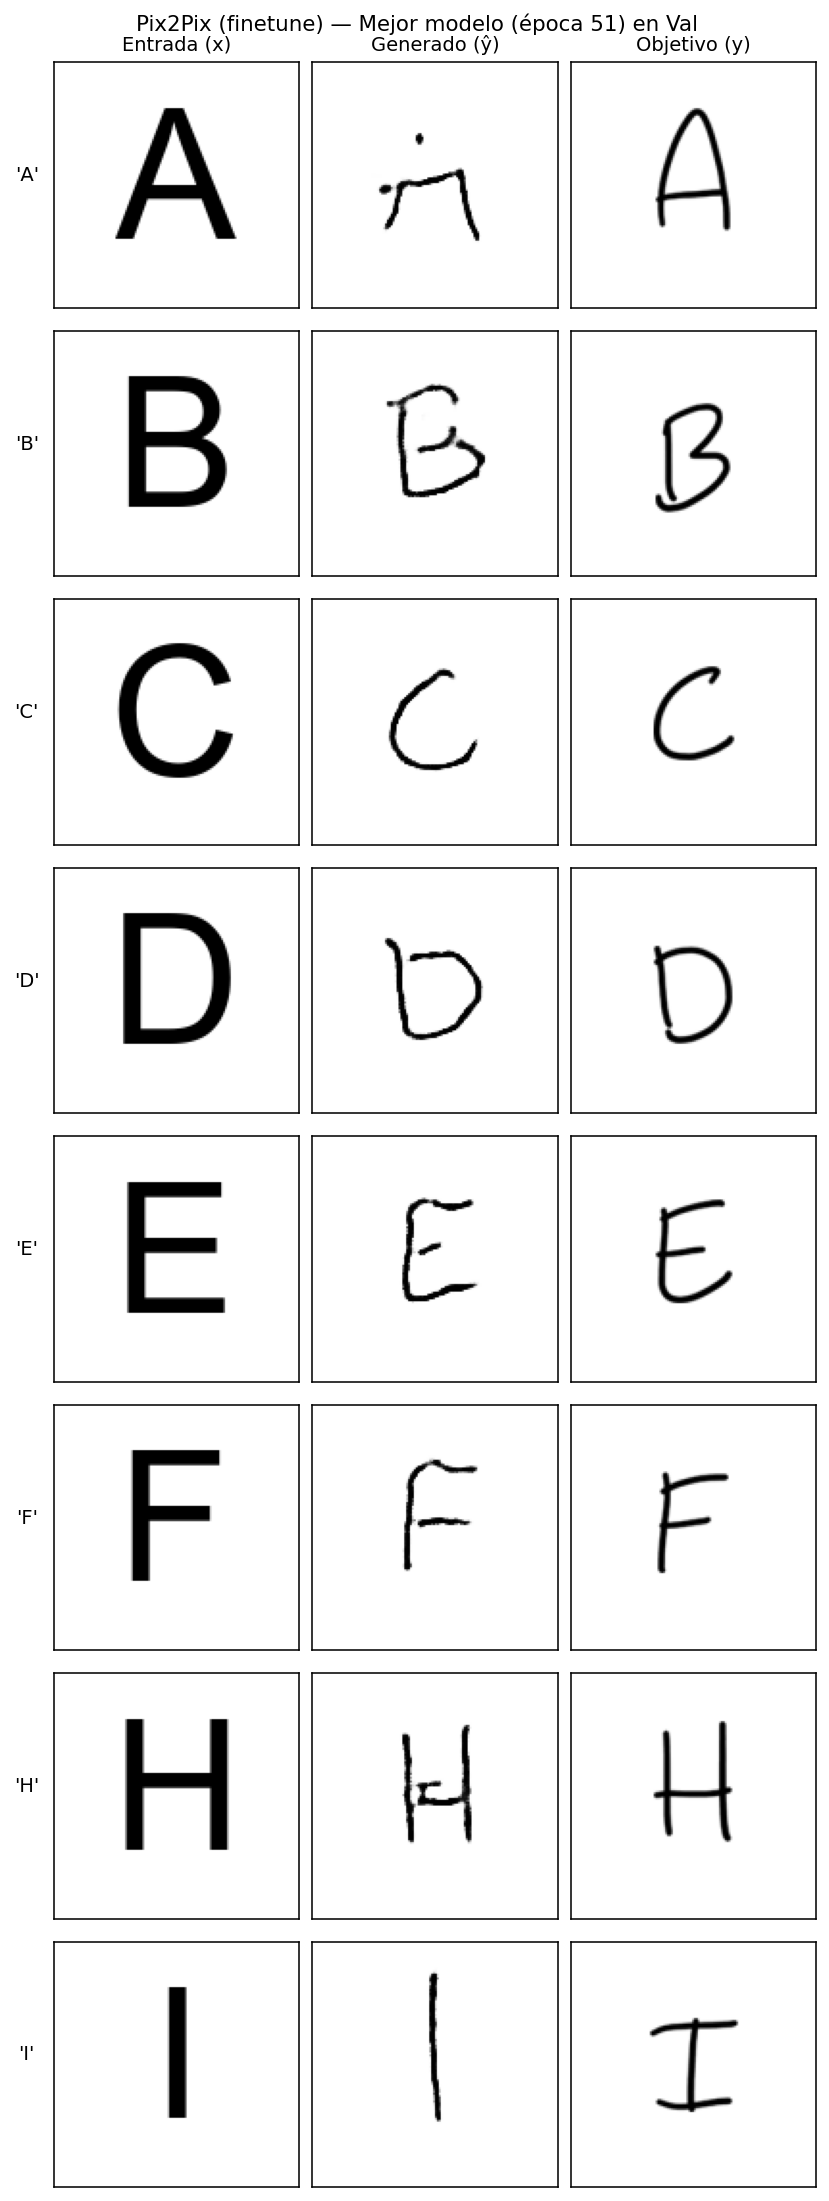


--- pix2pix_finetune_unseen_grid.png ---


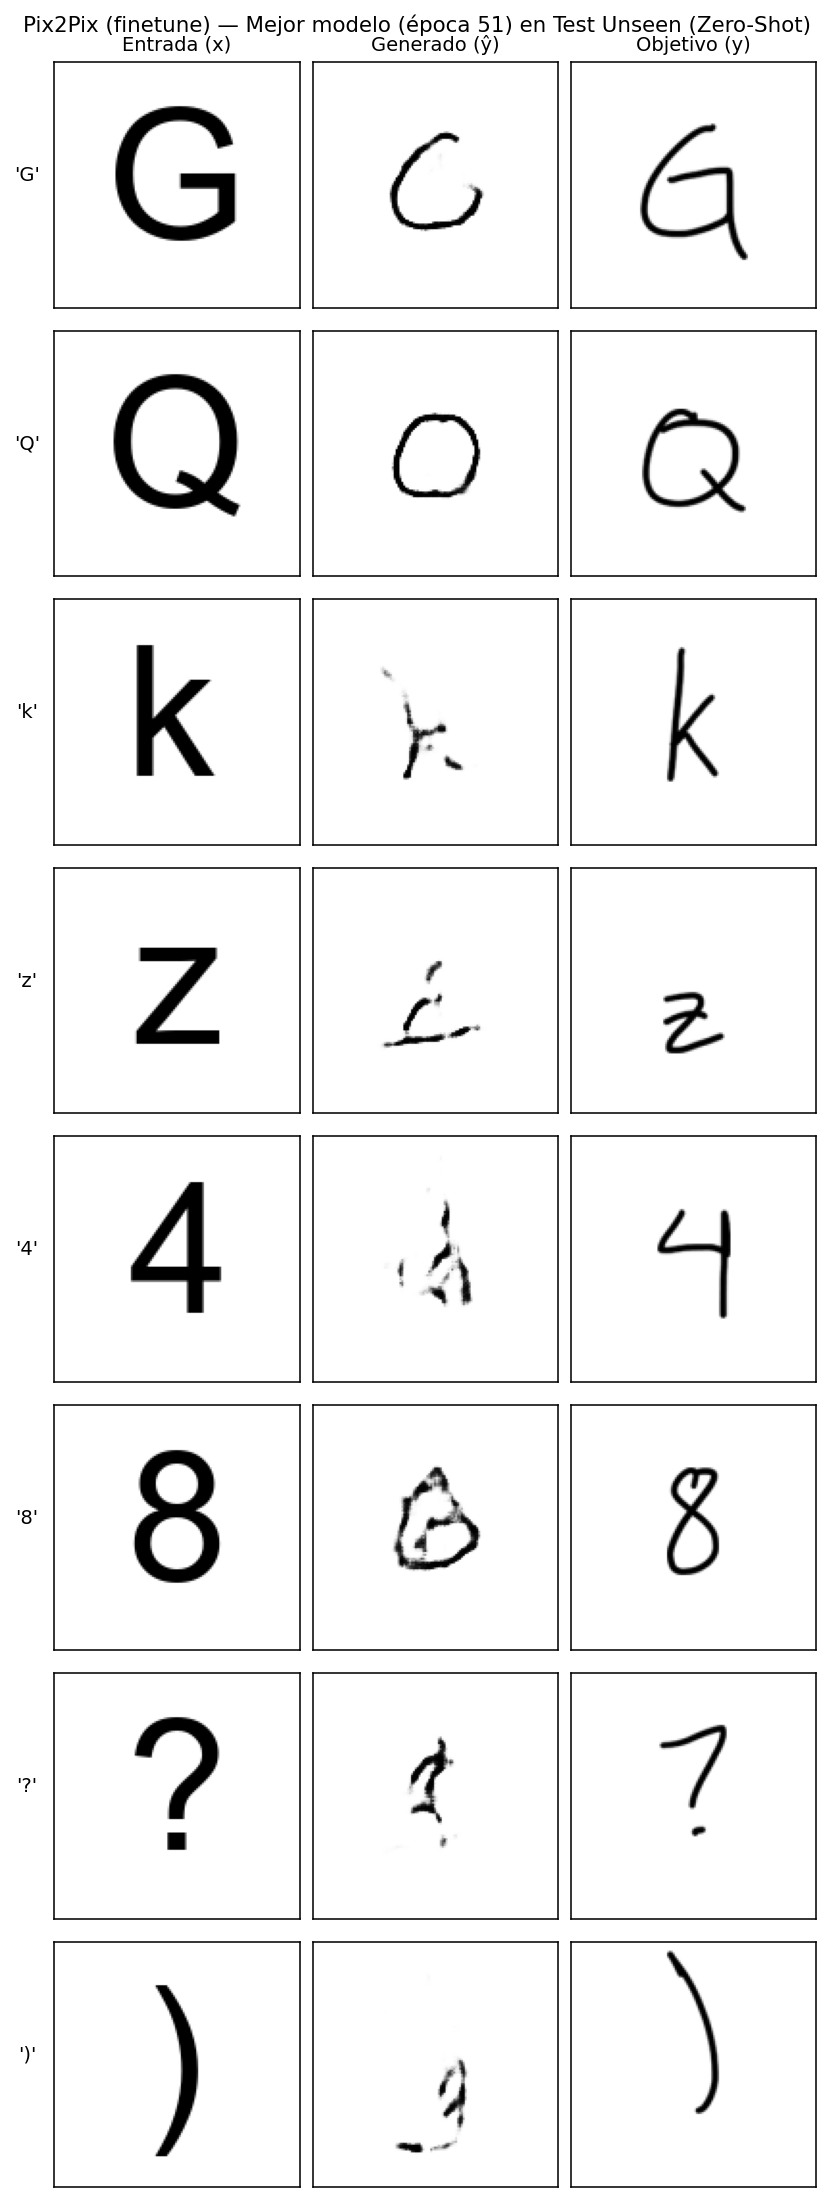


--- train_pix2pix_scratch.png ---


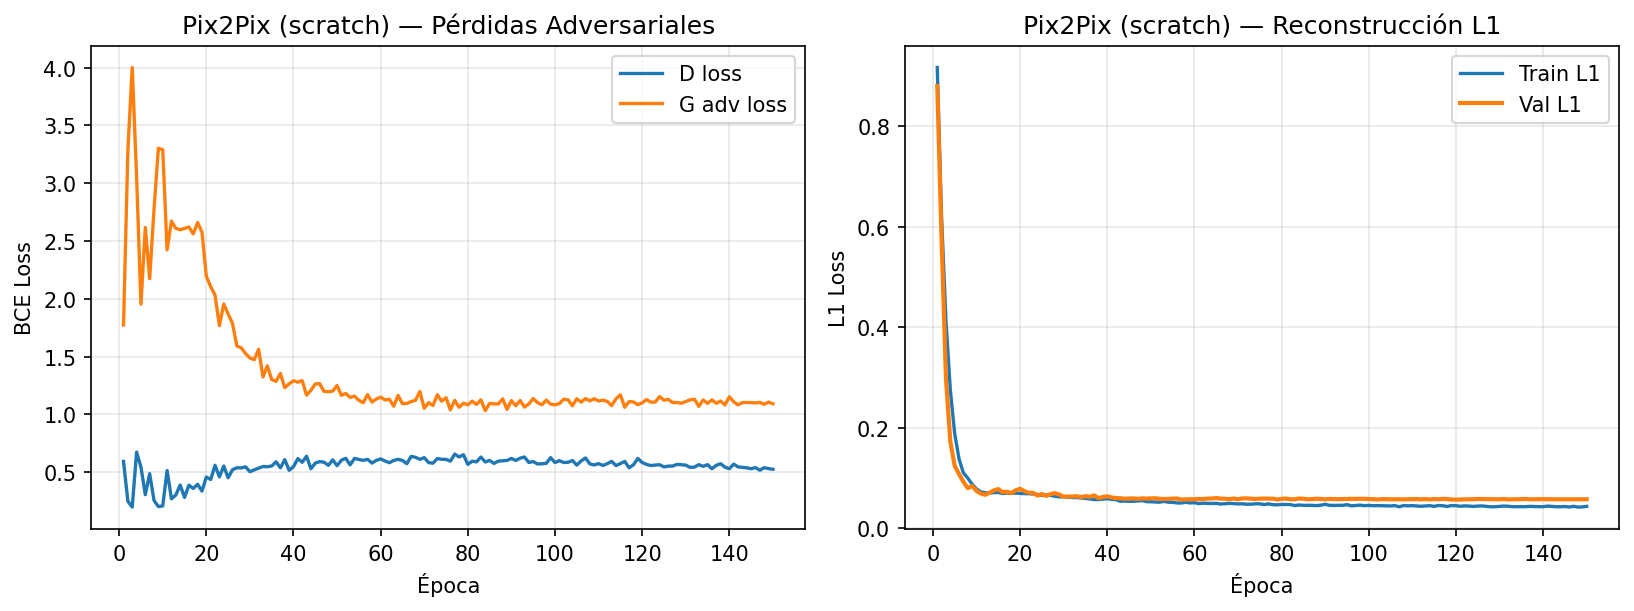


--- pix2pix_scratch_val_grid.png ---


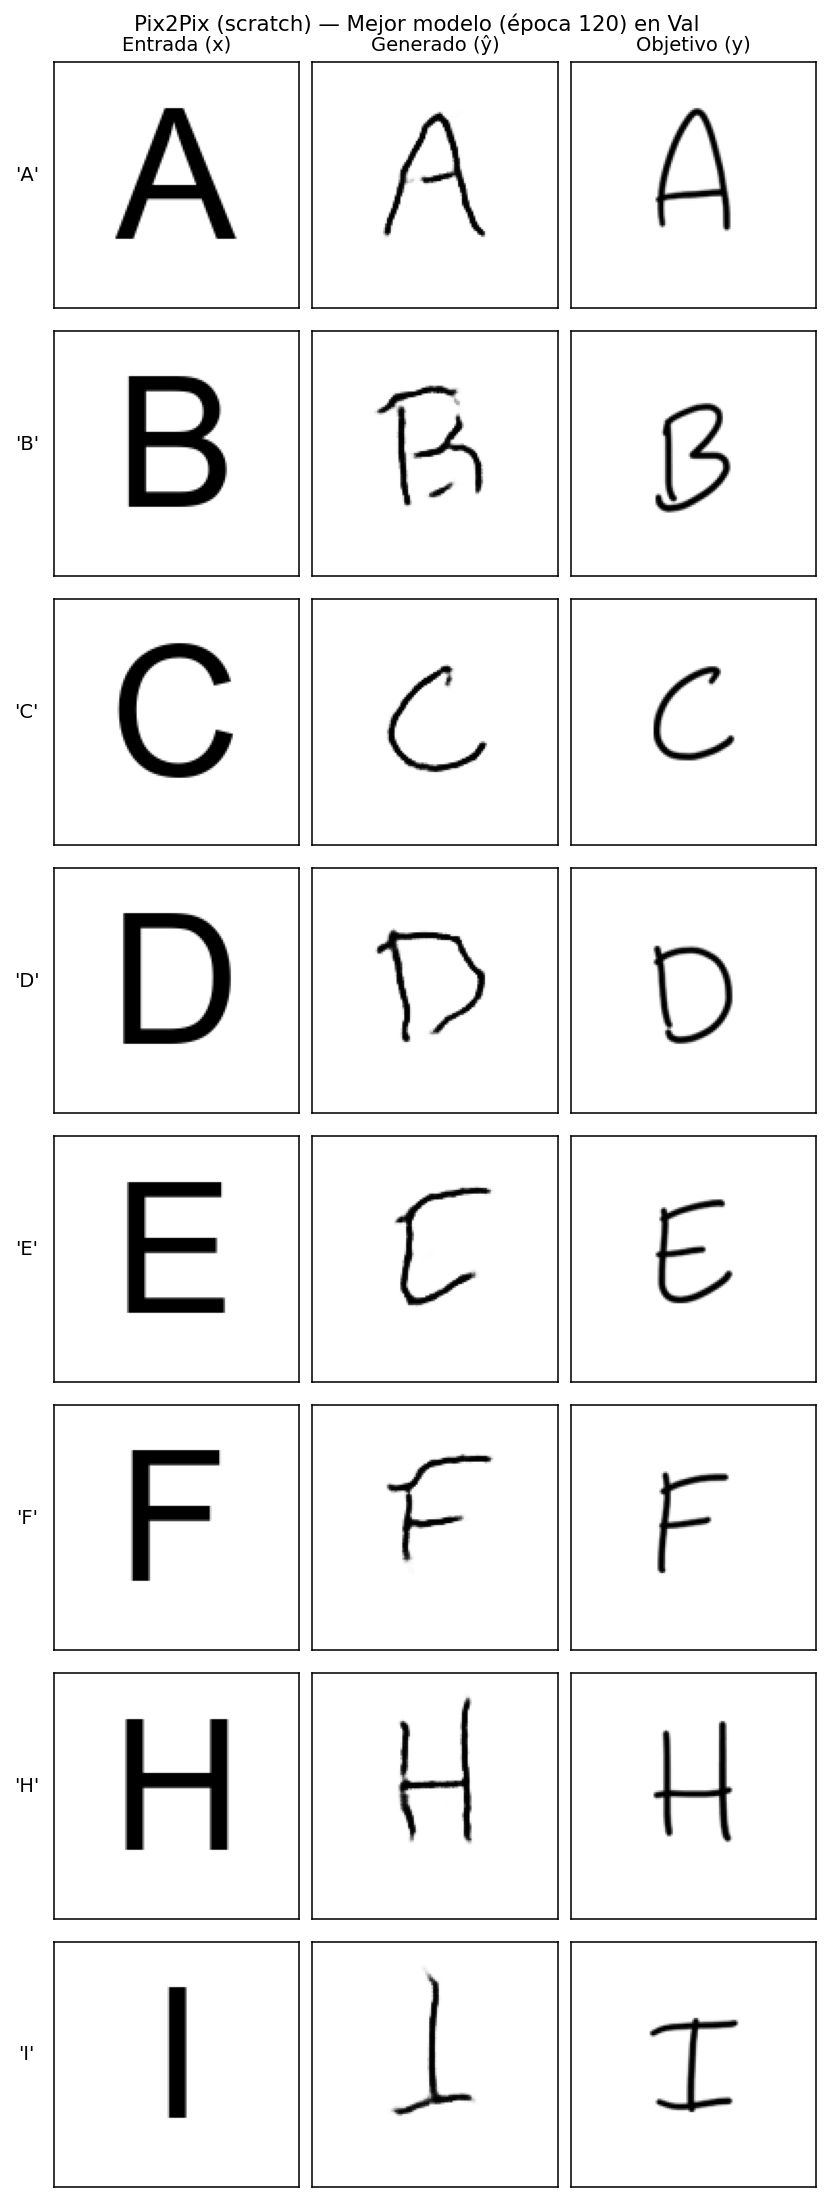


--- pix2pix_scratch_unseen_grid.png ---


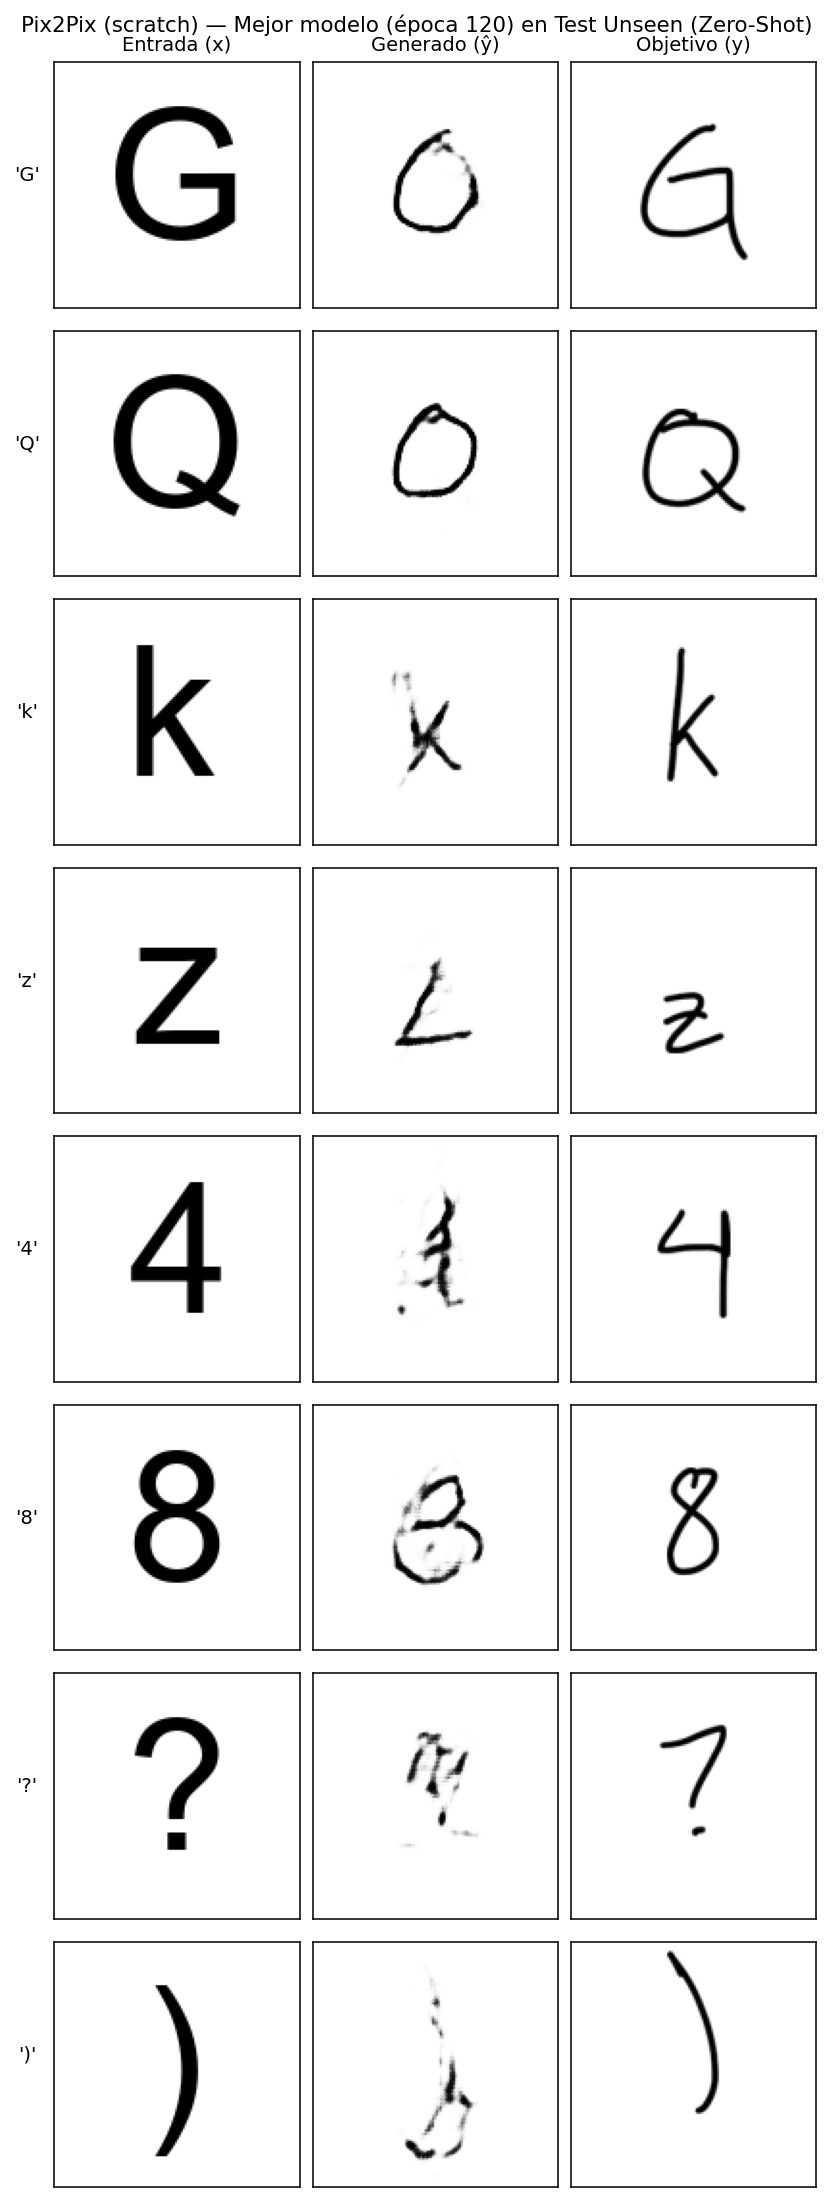

In [6]:
# 6. Inspeccionar curvas y cuadrículas x | ŷ | y generadas (Val y Test Unseen Zero-Shot)
from IPython.display import Image, display

fig_names = [
    "train_pix2pix_finetune.png",
    "pix2pix_finetune_val_grid.png",
    "pix2pix_finetune_unseen_grid.png",
    "train_pix2pix_scratch.png",
    "pix2pix_scratch_val_grid.png",
    "pix2pix_scratch_unseen_grid.png",
]

for fname in fig_names:
    fpath = FIG_DIR / fname
    if fpath.exists():
        print(f"\n--- {fname} ---")
        display(Image(filename=str(fpath)))

In [7]:
# 7. Evaluación cuantitativa comparativa sobre data/real_pairs (Jueces congelados ResNet-18 + EfficientNet-B0)
model_specs = [
    f"pretrained={CKPT_DIR / 'pix2pix_pretrained.pth'}",
]
if (CKPT_DIR / "pix2pix_scratch.pth").exists():
    model_specs.append(f"scratch={CKPT_DIR / 'pix2pix_scratch.pth'}")
if (CKPT_DIR / "pix2pix_finetuned.pth").exists():
    model_specs.append(f"finetune={CKPT_DIR / 'pix2pix_finetuned.pth'}")

models_arg = " ".join(f'"{m}"' for m in model_specs)
eval_cmd = (
    f"python -m eval.evaluate_models "
    f"--data-dir data/real_pairs "
    f"--models {models_arg} "
    f'--judges-dir "{CKPT_DIR}" '
    f'--results-dir "{RES_DIR / "eval"}" '
    f'--figures-dir "{FIG_DIR}" '
    f"--tag final"
)
print("Ejecutando:", eval_cmd)
get_ipython().system(eval_cmd)

summary_md = RES_DIR / "eval" / "summary_final.md"
if summary_md.exists():
    print("\n=== Resumen Cuantitativo Final ===\n")
    print(summary_md.read_text(encoding="utf-8"))

Ejecutando: python -m eval.evaluate_models --data-dir data/real_pairs --models "pretrained=/content/drive/MyDrive/handwritten-font-cgan/checkpoints/pix2pix_pretrained.pth" "scratch=/content/drive/MyDrive/handwritten-font-cgan/checkpoints/pix2pix_scratch.pth" "finetune=/content/drive/MyDrive/handwritten-font-cgan/checkpoints/pix2pix_finetuned.pth" --judges-dir "/content/drive/MyDrive/handwritten-font-cgan/checkpoints" --results-dir "/content/drive/MyDrive/handwritten-font-cgan/results/eval" --figures-dir "/content/drive/MyDrive/handwritten-font-cgan/figuras" --tag final
[INFO] Dispositivo: cuda | Dataset: data/real_pairs | Tag: final

=== Evaluando split 'val' (64 muestras) ===
  [reference_y  | resnet18       ] Acc= 89.06% | Macro-F1= 86.20% | Conf=0.824 | Pass>=0.70= 82.8% | FID=0.00 (ref)
  [reference_y  | efficientnet_b0] Acc= 84.38% | Macro-F1= 81.25% | Conf=0.804 | Pass>=0.70= 73.4% | FID=0.00 (ref)
  [pretrained   | resnet18       ] Acc= 71.88% | Macro-F1= 67.45% | Conf=0.717 | P